In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import datetime as dt
import numpy as np
from scipy.optimize import minimize, minimize_scalar, brentq
from scipy.stats import chi2, probplot, jarque_bera, skew, kurtosis, norm

from russian_rates.analysis import (
    load_rates,
)

In [2]:
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Откройте Jupyter из папки репозитория russian-interest-rate-models.")
DATA_DIR = ROOT / "data" / "processed"

data = load_rates(DATA_DIR)
ruonia = data["ruonia"]
key_rate = data["key_rate"]
zcyc = data["zcyc"]

In [3]:
ruonia_wide = ruonia.drop(columns='volume_bln_rub').sort_values(by="date", ascending=True).copy()
ruonia_wide["ruonia_pct"] = ruonia_wide["ruonia_pct"] / 100

In [4]:
ruonia_wide['r_prev'] = ruonia_wide["ruonia_pct"].shift(1)
ruonia_wide['dt'] = ((ruonia_wide['date'] - ruonia_wide['date'].shift(1)).dt.days.dropna().astype(int)) / 365
pairs = ruonia_wide.dropna(subset=["r_prev", "dt"]).copy()
assert (pairs["dt"] > 0).all()

In [5]:
r_prev = pairs["r_prev"].to_numpy(dtype=float)
r_next = pairs["ruonia_pct"].to_numpy(dtype=float)
dt = pairs["dt"].to_numpy(dtype=float)

In [6]:
def vasicek_nll(params, r_prev, r_next, dt):
    a, b, sigma = params

    if a <= 0 or sigma <= 0:
        return np.inf

    # Экспоненциальный коэффициент возврата
    phi = np.exp(-a * dt)

    # Условное математическое ожидание
    mu = b + (r_prev - b) * phi

    # Условная дисперсия
    var = (
        sigma**2
        * (-np.expm1(-2 * a * dt))
        / (2 * a)
    )

    # Отрицательное логарифмическое правдоподобие
    nll = 0.5 * np.sum(
        np.log(2 * np.pi * var)
        + (r_next - mu)**2 / var
    )

    return nll

In [7]:
params = [0.5, 0.1, 0.03]
vasicek_nll(params, r_prev, r_next, dt)

np.float64(-11489.751172016335)

In [8]:
# Поиск оптимальных параметров

# первоначальные приближения
a0 = 0.5
b0 = float(np.mean(r_next))

sigma0 = max(
    1e-5,
    float(np.sqrt(np.mean(
        (r_next - r_prev)**2 / dt
    )))
)

result = minimize(
    fun=vasicek_nll,
    x0=[a0, b0, sigma0],
    args=(r_prev, r_next, dt),
    method="L-BFGS-B",
    bounds=[
        (1e-5, 50), # a > 0
        (None, None), # b без ограничений
        (1e-6, None), # sigma > 0
    ]
)

if not result.success:
    raise RuntimeError(result.message)

print("Optimization success:", result.success)
print("Message:", result.message)

a, b, sigma = result.x

print(f"a = {a:.6f} 1/год")
print(f"b = {b * 100:.4f}%")
print(f"sigma = {sigma * 100:.4f} п.п./√год")

print(f"Half-life = {np.log(2) / a:.3f} года")
print(f"NLL = {result.fun:.4f}")

print("Parameters at bounds:")
print("a at upper bound:", np.isclose(a, 50))
print("sigma at lower bound:", np.isclose(sigma, 1e-6))

Optimization success: True
Message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
a = 0.778781 1/год
b = 11.3273%
sigma = 5.6725 п.п./√год
Half-life = 0.890 года
NLL = -13546.0864
Parameters at bounds:
a at upper bound: False
sigma at lower bound: False


In [9]:
for a0 in [0.1, 0.5, 1, 3, 10]:
    result = minimize(
        fun=vasicek_nll,
        x0=[a0, b0, sigma0],
        args=(r_prev, r_next, dt),
        method="L-BFGS-B",
        bounds=[
            (1e-5, 50),
            (None, None),
            (1e-6, None),
        ],
    )

    a, b, sigma = result.x

    print(
        f"a0={a0:5.2f} | "
        f"a={a:.5f} | "
        f"b={b*100:.3f}% | "
        f"sigma={sigma*100:.3f} | "
        f"NLL={result.fun:.4f} | "
        f"success={result.success}"
    )

a0= 0.10 | a=0.77877 | b=11.327% | sigma=5.673 | NLL=-13546.0864 | success=True
a0= 0.50 | a=0.77878 | b=11.327% | sigma=5.673 | NLL=-13546.0864 | success=True
a0= 1.00 | a=0.99945 | b=11.144% | sigma=5.676 | NLL=-13545.8804 | success=True
a0= 3.00 | a=0.77882 | b=11.327% | sigma=5.673 | NLL=-13546.0864 | success=True
a0=10.00 | a=0.77879 | b=11.327% | sigma=5.673 | NLL=-13546.0864 | success=True


a = 0.7788016403053939
NLL = -13546.086371929927


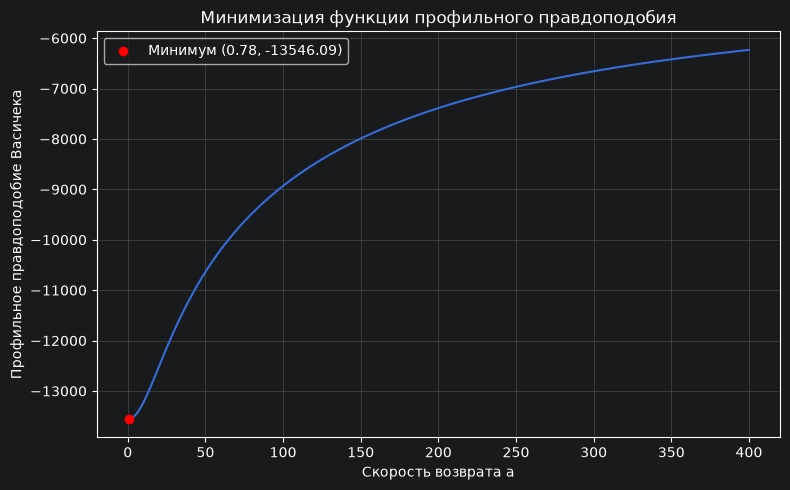

In [10]:
# Профильное правдоподобие - фиксирование a0 и подбор оптимальных b и σ
def profile_nll(a):
    phi = np.exp(-a * dt)

    q = -np.expm1(-2 * a * dt) / (2 * a)

    x = 1 - phi
    y = r_next - phi * r_prev

    # Оптимальный b при заданном a
    b = np.sum(x * y / q) / np.sum(x**2 / q)

    residuals = y - b * x

    # Оптимальный sigma при заданном a
    sigma2 = np.mean(residuals**2 / q)

    var = sigma2 * q

    nll = 0.5 * np.sum(
        np.log(2 * np.pi * var)
        + residuals**2 / var
    )

    return nll


result_profile = minimize_scalar(
    profile_nll,
    bounds=(0.01, 20),
    method="bounded"
)

print("a =", result_profile.x)
print("NLL =", result_profile.fun)



x_vals = np.linspace(0.01, 400, 3165)
y_vals = [profile_nll(x) for x in x_vals]

plt.figure(figsize=(8, 5))
plt.plot(x_vals, y_vals)
plt.scatter(
    result_profile.x,
    result_profile.fun,
    color="red",
    zorder=5,
    label=f"Минимум ({result_profile.x:.2f}, {result_profile.fun:.2f})"
)

plt.title("Минимизация функции профильного правдоподобия")
plt.xlabel("Скорость возврата a")
plt.ylabel("Профильное правдоподобие Васичека")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
# отдельная функция для модели Васичека
def calibrate_vasicek(df):
    df = df.sort_values("date").copy()

    r = df["ruonia_pct"].to_numpy()
    dates = df["date"]

    r_prev = r[:-1]
    r_next = r[1:]

    dt = (
        dates.diff().dt.days.iloc[1:].to_numpy() / 365
    )

    sigma0 = max(
        1e-5,
        np.sqrt(np.mean((r_next - r_prev)**2 / dt))
    )

    result = minimize(
        vasicek_nll,
        x0=[0.5, np.mean(r_next), sigma0],
        args=(r_prev, r_next, dt),
        method="L-BFGS-B",
        bounds=[
            (1e-5, 50),
            (None, None),
            (1e-6, None),
        ],
    )

    if not result.success:
        raise RuntimeError(result.message)

    return result.x

In [12]:
periods = {
    "2014–2026": ("2014-01-01", None),
    "2016–2021": ("2016-01-01", "2022-01-01"),
    "2022–2026": ("2022-01-01", None),
    "2023–2026": ("2023-01-01", None),
}

results = []

for name, (start, end) in periods.items():
    subset = ruonia_wide[
        ruonia_wide["date"] >= start
    ].copy()

    if end is not None:
        subset = subset[subset["date"] < end]

    a, b, sigma = calibrate_vasicek(subset)

    results.append({
        "Период": name,
        "a": a,
        "b, %": b * 100,
        "sigma, п.п./√год": sigma * 100,
        "Half-life, мес.": np.log(2) / a * 12,
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Период,a,"b, %","sigma, п.п./√год","Half-life, мес."
0,2014–2026,0.7788,11.3273,5.6725,10.6805
1,2016–2021,0.9850,6.9022,2.5126,8.4440
2,2022–2026,0.8099,15.7350,5.0938,10.2707
3,2023–2026,0.8263,17.2882,3.5535,10.0658


In [13]:
def profile_params(a, r_prev, r_next, dt):
    phi = np.exp(-a * dt)

    x = -np.expm1(-a * dt)
    q = -np.expm1(-2 * a * dt) / (2 * a)

    y = r_next - phi * r_prev

    # Оптимальное b при фиксированном a
    b = np.sum(x * y / q) / np.sum(x**2 / q)

    residuals = y - b * x

    # Оптимальная дисперсия шума
    sigma2 = np.mean(residuals**2 / q)

    var = sigma2 * q

    nll = 0.5 * np.sum(
        np.log(2 * np.pi * var)
        + residuals**2 / var
    )

    return b, np.sqrt(sigma2), nll

In [14]:
def calibrate_profile(r_prev, r_next, dt):
    bounds = (0.001, 20.0)

    def objective(a):
        return profile_params(
            a, r_prev, r_next, dt
        )[2]

    result = minimize_scalar(
        objective,
        bounds=bounds,
        method="bounded"
    )

    if not result.success:
        raise RuntimeError(result.message)

    a = result.x

    b, sigma, min_nll = profile_params(
        a, r_prev, r_next, dt
    )

    # Граница 95%-го доверительного интервала
    threshold = min_nll + chi2.ppf(0.95, 1) / 2

    def find_bound(left, right):
        def f(x):
            return objective(x) - threshold

        if f(left) * f(right) >= 0:
            return np.nan

        return brentq(f, left, right)

    a_lower = find_bound(bounds[0], a)
    a_upper = find_bound(a, bounds[1])

    return {
        "a": a,
        "b": b,
        "sigma": sigma,
        "nll": min_nll,
        "a_lower": a_lower,
        "a_upper": a_upper
    }

In [15]:
fit = calibrate_profile(r_prev, r_next, dt)

print(f"a = {fit['a']:.4f}")
print(f"b = {fit['b'] * 100:.4f}%")
print(f"sigma = {fit['sigma'] * 100:.4f}")

print(
    f"95% CI(a): "
    f"[{fit['a_lower']:.4f}, "
    f"{fit['a_upper']:.4f}]"
)

print(
    f"Half-life = "
    f"{np.log(2) / fit['a'] * 12:.2f} мес."
)

a = 0.7788
b = 11.3273%
sigma = 5.6725
95% CI(a): [0.1061, 1.4534]
Half-life = 10.68 мес.


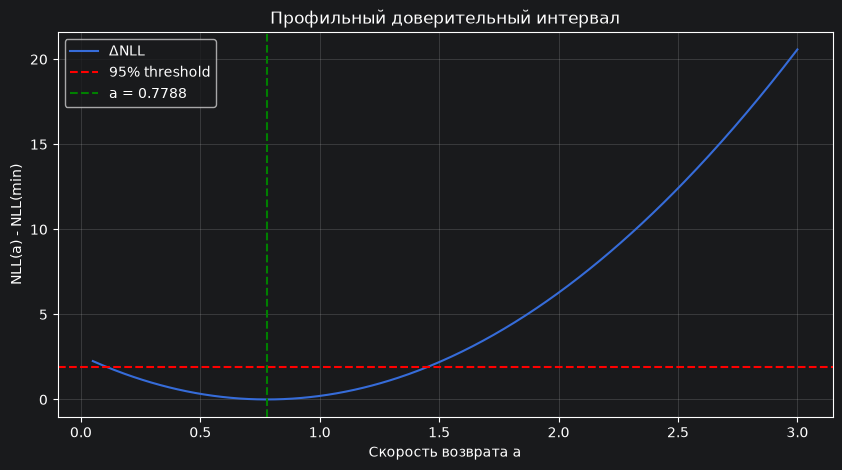

In [16]:
a_grid = np.linspace(0.05, 3, 400)

nll_values = np.array([
    profile_params(
        a, r_prev, r_next, dt
    )[2]
    for a in a_grid
])

delta_nll = nll_values - fit["nll"]

plt.figure(figsize=(10, 5))

plt.plot(a_grid, delta_nll, label="ΔNLL")

plt.axhline(
    chi2.ppf(0.95, 1) / 2,
    color="red",
    linestyle="--",
    label="95% threshold"
)

plt.axvline(
    fit["a"],
    color="green",
    linestyle="--",
    label=f"a = {fit['a']:.4f}"
)

plt.xlabel("Скорость возврата a")
plt.ylabel("NLL(a) - NLL(min)")
plt.title("Профильный доверительный интервал")

plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [17]:
a = fit["a"]
b = fit["b"]
sigma = fit["sigma"]

phi = np.exp(-a * dt)

mu = b + (r_prev - b) * phi

var = (
    sigma**2
    * (-np.expm1(-2 * a * dt))
    / (2 * a)
)

z = (r_next - mu) / np.sqrt(var)

print(f"Среднее остатков: {np.mean(z):.4f}")
print(f"Ст. отклонение: {np.std(z):.4f}")
print(f"Минимум: {np.min(z):.4f}")
print(f"Максимум: {np.max(z):.4f}")
print(f"|z| > 3: {np.sum(np.abs(z) > 3)}")

Среднее остатков: -0.0027
Ст. отклонение: 1.0000
Минимум: -14.5419
Максимум: 23.0991
|z| > 3: 22


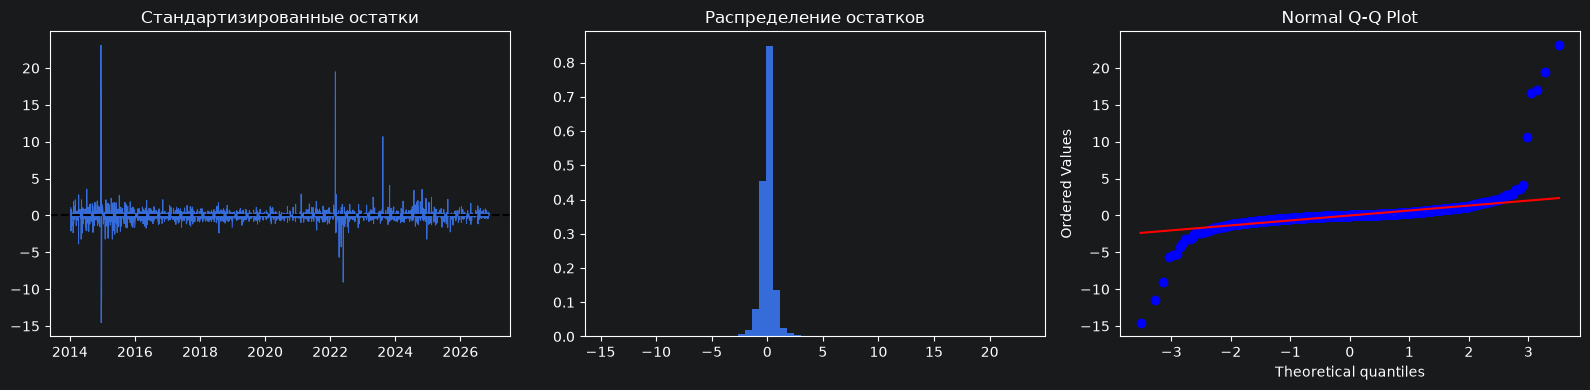

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Историческая динамика остатков
axes[0].plot(pairs["date"], z, linewidth=0.7)
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_title("Стандартизированные остатки")

# Распределение
axes[1].hist(z, bins=60, density=True)
axes[1].set_title("Распределение остатков")

# Проверка нормальности
probplot(z, dist="norm", plot=axes[2])
axes[2].set_title("Normal Q-Q Plot")

plt.tight_layout()
plt.show()

In [19]:
residuals = pd.Series(z)

for lag in [1, 5, 10, 20]:
    print(
        f"Autocorrelation lag={lag}: "
        f"{residuals.autocorr(lag):.4f}"
    )

jb = jarque_bera(z)

print("\nJarque-Bera:")
print(f"Statistic: {jb.statistic:.4f}")
print(f"P-value: {jb.pvalue:.6f}")

Autocorrelation lag=1: 0.2072
Autocorrelation lag=5: -0.1375
Autocorrelation lag=10: 0.0052
Autocorrelation lag=20: -0.0021

Jarque-Bera:
Statistic: 5939433.2037
P-value: 0.000000


In [20]:
periods = {
    "2014–2026": ("2014-01-01", None),
    "2016–2021": ("2016-01-01", "2022-01-01"),
    "2022–2026": ("2022-01-01", None),
    "2023–2026": ("2023-01-01", None)
}

results = []

for name, (start, end) in periods.items():
    subset = ruonia_wide[
        ruonia_wide["date"] >= start
    ].copy()

    if end is not None:
        subset = subset[subset["date"] < end]

    subset = subset.sort_values("date")

    rates = subset["ruonia_pct"].to_numpy()

    r0 = rates[:-1]
    r1 = rates[1:]

    delta = (
        subset["date"].diff().dt.days
        .iloc[1:].to_numpy() / 365
    )

    if len(delta) < 30 or not np.all(delta > 0):
        raise ValueError(
            f"Недостаточно данных или неверные даты: {name}"
        )

    res = calibrate_profile(r0, r1, delta)

    results.append({
        "Период": name,
        "a": res["a"],
        "a lower": res["a_lower"],
        "a upper": res["a_upper"],
        "b, %": res["b"] * 100,
        "sigma": res["sigma"] * 100,
        "Half-life, мес.": np.log(2) / res["a"] * 12,
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Период,a,a lower,a upper,"b, %",sigma,"Half-life, мес."
0,2014–2026,0.7788,0.1061,1.4534,11.3273,5.6725,10.6802
1,2016–2021,0.9850,NaN,1.9741,6.9022,2.5126,8.4441
2,2022–2026,0.8099,NaN,1.8056,15.7350,5.0938,10.2706
3,2023–2026,0.8264,NaN,1.6869,17.2856,3.5535,10.0654


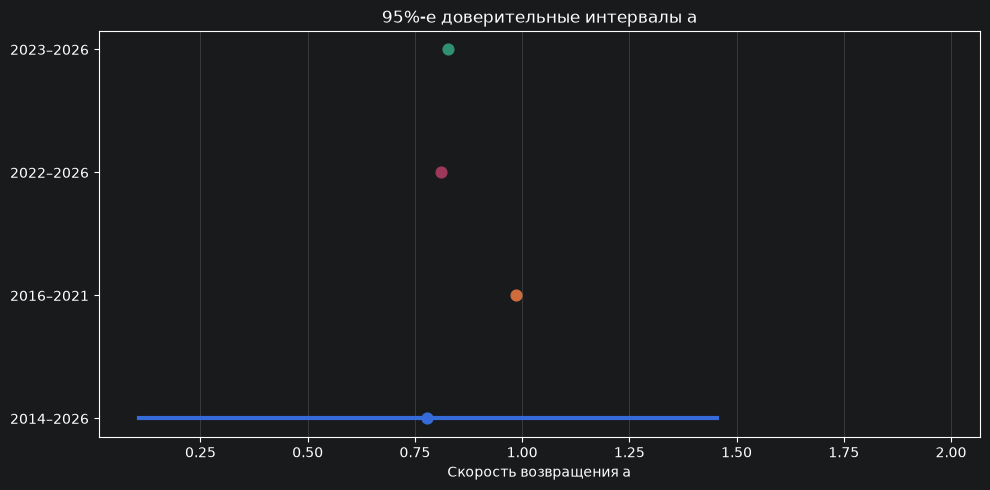

In [21]:
plt.figure(figsize=(10, 5))

for i, row in results_df.iterrows():
    plt.plot(
        [row["a lower"], row["a upper"]],
        [i, i],
        linewidth=3
    )

    plt.scatter(row["a"], i, s=60)

plt.yticks(
    range(len(results_df)),
    results_df["Период"]
)

plt.xlabel("Скорость возвращения a")
plt.title("95%-е доверительные интервалы a")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
def period_pairs(start, end=None):
    subset = ruonia_wide[
        ruonia_wide["date"] >= start
    ].copy()

    if end is not None:
        subset = subset[subset["date"] < end]

    subset = subset.sort_values("date")

    rates = subset["ruonia_pct"].to_numpy()
    times = (
        subset["date"].diff().dt.days
        .iloc[1:].to_numpy() / 365
    )

    return rates[:-1], rates[1:], times


p1 = period_pairs("2016-01-01", "2022-01-01")
p2 = period_pairs("2022-01-01")

# Две независимые калибровки
fit1 = calibrate_profile(*p1)
fit2 = calibrate_profile(*p2)

nll_separate = fit1["nll"] + fit2["nll"]

# Один набор параметров для тех же переходов
r0 = np.concatenate([p1[0], p2[0]])
r1 = np.concatenate([p1[1], p2[1]])
delta = np.concatenate([p1[2], p2[2]])

fit_common = calibrate_profile(r0, r1, delta)

# Информационный критерий Акаике
# AIC = 2k + 2NLL
aic_common = 2 * 3 + 2 * fit_common["nll"]
aic_separate = 2 * 6 + 2 * nll_separate

print(f"AIC общей модели: {aic_common:.2f}")
print(f"AIC раздельной модели: {aic_separate:.2f}")

print(
    "Разница AIC (общая - раздельная):",
    round(aic_common - aic_separate, 2)
)

AIC общей модели: -24876.58
AIC раздельной модели: -25515.35
Разница AIC (общая - раздельная): 638.76


In [23]:
# Проверяем форму распределения
print(f"Skewness: {skew(z):.4f}")
print(f"Kurtosis: {kurtosis(z, fisher=False):.4f}")

# Сопоставляем остатки с историческими датами
diagnostics = pd.DataFrame({
    "date": pairs["date"].to_numpy(),
    "ruonia_prev_pct": r_prev * 100,
    "ruonia_pct": r_next * 100,
    "gap_days": dt * 365,
    "z": z,
})

diagnostics["abs_z"] = diagnostics["z"].abs()

# 20 наиболее экстремальных наблюдений
display(
    diagnostics.nlargest(20, "abs_z")[
        ["date", "ruonia_prev_pct",
         "ruonia_pct", "gap_days", "z"]
    ]
)

Skewness: 7.8094
Kurtosis: 214.6469


,date,ruonia_prev_pct,ruonia_pct,gap_days,z
234,2014-12-16,11.84,18.69,1.0,23.099053
1995,2022-02-28,10.00,20.00,3.0,19.490864
236,2014-12-18,23.62,28.65,1.0,17.047420
235,2014-12-17,18.69,23.62,1.0,16.674833
237,2014-12-19,28.65,24.30,1.0,-14.541916
239,2014-12-23,23.36,19.93,1.0,-11.478072
2356,2023-08-15,8.51,11.69,1.0,10.701400
2054,2022-05-27,13.34,10.65,1.0,-9.055104
2024,2022-04-11,19.24,16.28,3.0,-5.675696
241,2014-12-25,18.37,16.75,1.0,-5.411360


In [24]:
diagnostics["year"] = diagnostics["date"].dt.year

yearly = diagnostics.groupby("year").agg(
    observations=("z", "count"),
    mean_z=("z", "mean"),
    std_z=("z", "std"),
    extreme_3sigma=("z", lambda x: (x.abs() > 3).sum()),
    extreme_5sigma=("z", lambda x: (x.abs() > 5).sum()),
    max_abs_z=("z", lambda x: x.abs().max()),
)

display(yearly.round(3))

,observations,mean_z,std_z,extreme_3sigma,extreme_5sigma,max_abs_z
year,,,,,,
2014,245,0.080,2.647,10,7,23.099
2015,246,-0.084,0.881,3,0,3.214
2016,246,-0.010,0.500,0,0,2.144
2017,246,-0.051,0.474,0,0,1.597
2018,246,-0.038,0.458,0,0,2.386
2019,246,-0.049,0.343,0,0,1.339
2020,240,-0.062,0.342,0,0,1.529
2021,246,-0.004,0.508,0,0,2.909
2022,246,-0.006,1.557,4,3,19.491


In [25]:
def diagnose_vasicek_period(df, start, end=None):
    # Отбираем нужный период
    subset = df.loc[
        df["date"] >= start,
        ["date", "ruonia_pct"]
    ].copy()

    if end is not None:
        subset = subset[subset["date"] < end]

    subset = subset.sort_values("date")

    if len(subset) < 30:
        raise ValueError("Недостаточно наблюдений")

    if subset["date"].duplicated().any():
        raise ValueError("Обнаружены повторяющиеся даты")

    if subset["ruonia_pct"].isna().any():
        raise ValueError("Обнаружены пропущенные ставки")

    # Ставки уже в долях единицы
    rates = subset["ruonia_pct"].to_numpy()

    r0 = rates[:-1]
    r1 = rates[1:]

    dt = (
        subset["date"].diff().dt.days
        .iloc[1:].to_numpy() / 365
    )

    if not np.all(dt > 0):
        raise ValueError("Некорректные временные интервалы")

    # Независимая калибровка для периода
    fit = calibrate_profile(r0, r1, dt)

    a = fit["a"]
    b = fit["b"]
    sigma = fit["sigma"]

    # Условное математическое ожидание
    phi = np.exp(-a * dt)
    mu = b + (r0 - b) * phi

    # Условная дисперсия
    var = (
        sigma**2
        * (-np.expm1(-2 * a * dt))
        / (2 * a)
    )

    # Стандартизированные остатки
    z = (r1 - mu) / np.sqrt(var)

    return {
        "fit": fit,
        "dates": subset["date"].iloc[1:].to_numpy(),
        "z": z,
        "r_prev": r0,
        "r_next": r1
    }

In [26]:
periods = {
    "2016–2021": ("2016-01-01", "2022-01-01"),
    "2022–2026": ("2022-01-01", None),
    "2023–2026": ("2023-01-01", None),
}

diagnostics_by_period = {}
results = []

for name, (start, end) in periods.items():

    diag = diagnose_vasicek_period(
        ruonia_wide, start, end
    )

    diagnostics_by_period[name] = diag

    fit = diag["fit"]
    z = diag["z"]

    jb = jarque_bera(z)
    residuals = pd.Series(z)

    results.append({
        "Период": name,
        "Наблюдений": len(z),
        "a": fit["a"],
        "b, %": fit["b"] * 100,
        "sigma": fit["sigma"] * 100,
        "Skewness": skew(z),
        "Kurtosis": kurtosis(z, fisher=False),
        "JB": jb.statistic,
        "p-value": jb.pvalue,
        "ACF(1)": residuals.autocorr(lag=1),
        "ACF(|z|, 1)": residuals.abs().autocorr(lag=1),
        "|z| > 3": np.sum(np.abs(z) > 3),
        "|z| > 5": np.sum(np.abs(z) > 5),
    })

diagnostics_df = pd.DataFrame(results)

display(diagnostics_df.round(4))

,Период,Наблюдений,a,"b, %",sigma,Skewness,Kurtosis,JB,p-value,ACF(1),"ACF(|z|, 1)",|z| > 3,|z| > 5
0,2016–2021,1469,0.9850,6.9022,2.5126,0.3094,6.9501,9.785138e+02,0.0,-0.0425,0.1926,18,2
1,2022–2026,1203,0.8099,15.7350,5.0938,8.8251,211.1268,2.186869e+06,0.0,0.0661,0.1146,10,4
2,2023–2026,957,0.8264,17.2856,3.5535,5.8056,94.3410,3.380605e+05,0.0,0.0340,0.1268,12,5


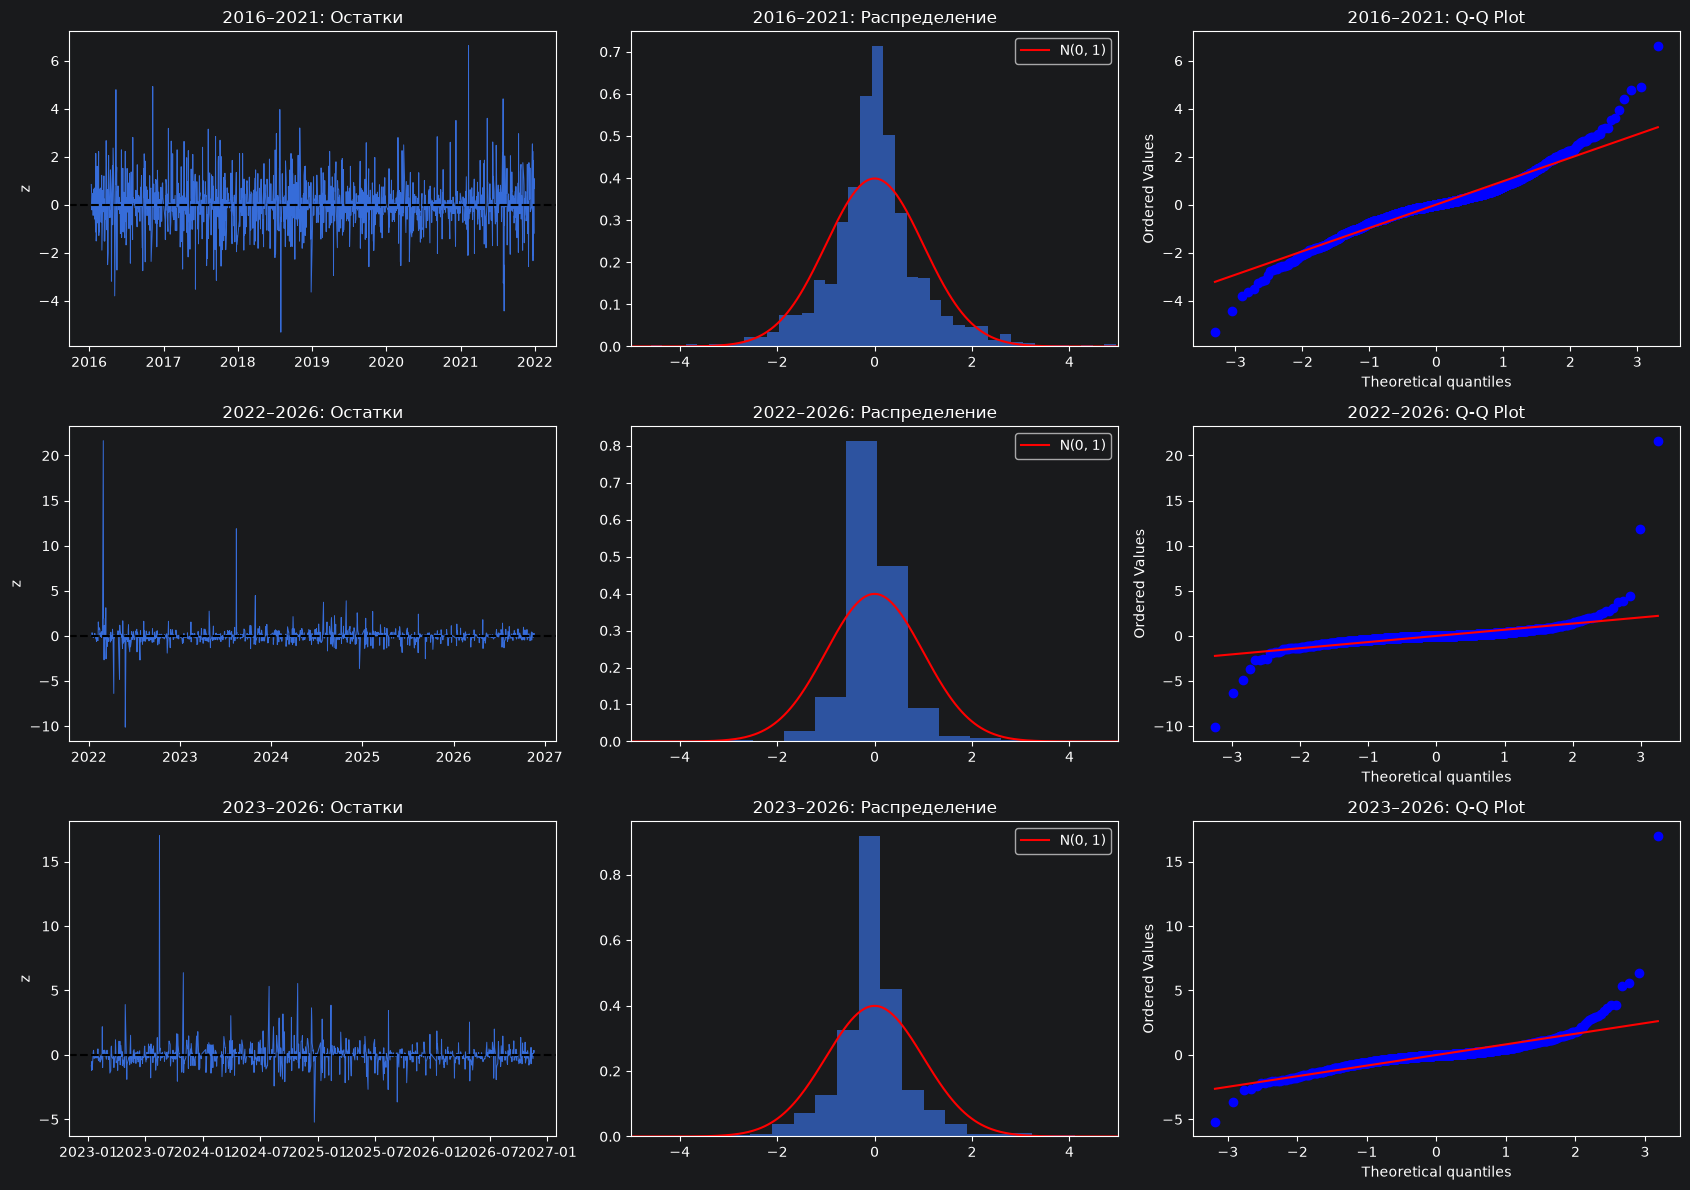

In [27]:
fig, axes = plt.subplots(
    len(periods), 3,
    figsize=(17, 12)
)

for i, (name, diag) in enumerate(
    diagnostics_by_period.items()
):
    z = diag["z"]
    dates = diag["dates"]

    # 1. Остатки во времени
    axes[i, 0].plot(dates, z, linewidth=0.7)
    axes[i, 0].axhline(0, color="black", linestyle="--")
    axes[i, 0].set_title(f"{name}: Остатки")
    axes[i, 0].set_ylabel("z")

    # 2. Гистограмма
    axes[i, 1].hist(
        z,
        bins=50,
        density=True,
        alpha=0.7
    )

    x = np.linspace(-5, 5, 300)

    axes[i, 1].plot(
        x, norm.pdf(x),
        color="red",
        label="N(0, 1)"
    )

    axes[i, 1].set_xlim(-5, 5)
    axes[i, 1].set_title(f"{name}: Распределение")
    axes[i, 1].legend()

    # 3. Q-Q Plot
    probplot(z, dist="norm", plot=axes[i, 2])
    axes[i, 2].set_title(f"{name}: Q-Q Plot")

plt.tight_layout()
plt.show()

In [28]:
for name, diag in diagnostics_by_period.items():

    print(f"\n{name}")

    z = diag["z"]

    extreme = pd.DataFrame({
        "date": diag["dates"],
        "ruonia_prev": diag["r_prev"] * 100,
        "ruonia_next": diag["r_next"] * 100,
        "z": z,
        "abs_z": np.abs(z)
    })

    display(
        extreme.nlargest(5, "abs_z")[
            ["date", "ruonia_prev", "ruonia_next", "z"]
        ].round(4)
    )


2016–2021


,date,ruonia_prev,ruonia_next,z
1244,2021-02-09,3.28,4.16,6.6260
630,2018-08-01,7.74,7.04,-5.3126
208,2016-11-09,9.37,10.01,4.9236
81,2016-05-12,10.38,11.00,4.7920
1364,2021-08-03,6.19,5.61,-4.4307



2022–2026


,date,ruonia_prev,ruonia_next,z
33,2022-02-28,10.00,20.00,21.6435
394,2023-08-15,8.51,11.69,11.8800
92,2022-05-27,13.34,10.65,-10.1202
62,2022-04-11,19.24,16.28,-6.3804
77,2022-05-04,16.56,13.68,-4.8421



2023–2026


,date,ruonia_prev,ruonia_next,z
148,2023-08-15,8.51,11.69,17.0092
202,2023-10-30,12.67,14.75,6.3810
447,2024-10-28,18.72,20.49,5.5430
382,2024-07-29,15.55,17.27,5.3205
486,2024-12-20,21.97,20.99,-5.2177


In [29]:
for name, diag in diagnostics_by_period.items():
    z = pd.Series(diag["z"], dtype=float)

    # Только диагностический эксперимент
    trimmed = z.where(z.abs() <= 5)
    valid = trimmed.dropna()

    print(f"\n{name}")
    print(f"Исключено: {z.notna().sum() - len(valid)}")
    print(f"Kurtosis исходный: {kurtosis(z, fisher=False):.2f}")
    print(f"Kurtosis без |z| > 5: {kurtosis(valid, fisher=False):.2f}")
    print(f"ACF(|z|, 1) исходный: {z.abs().autocorr(1):.4f}")
    print(f"ACF(|z|, 1) без выбросов: {trimmed.abs().autocorr(1):.4f}")


2016–2021
Исключено: 2
Kurtosis исходный: 6.95
Kurtosis без |z| > 5: 5.63
ACF(|z|, 1) исходный: 0.1926
ACF(|z|, 1) без выбросов: 0.2015

2022–2026
Исключено: 4
Kurtosis исходный: 211.13
Kurtosis без |z| > 5: 14.62
ACF(|z|, 1) исходный: 0.1146
ACF(|z|, 1) без выбросов: 0.2452

2023–2026
Исключено: 5
Kurtosis исходный: 94.34
Kurtosis без |z| > 5: 7.73
ACF(|z|, 1) исходный: 0.1268
ACF(|z|, 1) без выбросов: 0.2861
